# Chung et al. 2017 — Breast Cancer
## 04 · EMT-TF expression (unconditional final step)

Categorical overlay of thresholded EMT-TF expressers on the grey manifold. Panel candidates span the Snail/Zeb/Twist, **FOXC**, and **PRRX** families (VIM is a mesenchymal marker, not a TF -> excluded). TFs are gated on detectable expression; the two most arm-specific expressed factors (early/root vs late/terminus) are shown.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 309 | pseudotime range 0.0 -> 7.72


### Candidate EMT-TF panel — detection-gated, scored by pseudotime position
Report detection fraction, early/late means, and rho vs pseudotime; keep factors expressed in > 3% of cells.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('panel genes present:', present)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

panel genes present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'FOXC1', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.149       0.325      0.234    -0.082    EARLY(root)
 PRRX1      0.029       0.089      0.041    -0.054    EARLY(root)
 PRRX2      0.032       0.033      0.046     0.033 LATE(terminus)
 SNAI2      0.045       0.187      0.169     0.036    EARLY(root)
TWIST1      0.097       0.156      0.264     0.041 LATE(terminus)
  ZEB2      0.227       0.224      0.368     0.061 LATE(terminus)
  ZEB1      0.165       0.211      0.427     0.086 LATE(terminus)
 SNAI1      0.207       0.282      0.626     0.130 LATE(terminus)

derived pair: FOXC1 (early/root) <-> SNAI1 (late/terminus)


### Categorical overlay on the grey manifold (deliverable)
Display cutoff = upper quartile among expressers (set, not outlier-dominated); thresholded expressers coloured over all cells in grey. House style (3.5,1.5), size=30.

overlay thresholds (upper quartile among expressers): {'FOXC1': 3.094, 'SNAI1': 3.571} | cells shown: {'FOXC1': 12, 'SNAI1': 16}
FOXC1: 14.9% expressing; 12 shown (upper quartile), mean pseudotime of shown cells = 0.54 (all = 0.56)
SNAI1: 20.7% expressing; 16 shown (upper quartile), mean pseudotime of shown cells = 0.57 (all = 0.56)
shown-cell pseudotime separation (FOXC1 vs SNAI1) = 0.02
saved expression.pdf


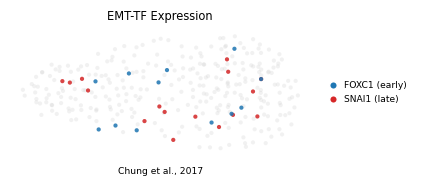

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[early_tf],markersize=5,label=f'{early_tf} (early)'),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[late_tf],markersize=5,label=f'{late_tf} (late)')],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5,-.14,'Chung et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')